# Proyecto Primer Parcial — Aporte individual

**Estudiante:** Jeremy Freddy González Baquerizo  
**Grupo:** D  
**Paralelo:** CDDEIA-ELNO-4-2  
**Responsabilidad:** Regresión lineal múltiple A/B  
**Dataset:** `student-mat.csv` (395 estudiantes)

**Nota:** Este notebook es una base completa y ejecutable de la sección asignada. Revísala, realiza tus cambios reales y registra el commit desde tu propia cuenta. No presentes como propio trabajo que no hayas revisado y comprendido.

## Preparación común para ejecutar de forma independiente
Estas celdas de configuración y carga de datos son compartidas como apoyo técnico; la sección atribuible a este integrante comienza más abajo.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression, RidgeCV, LassoCV
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             accuracy_score, precision_score, recall_score, confusion_matrix)
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

SEMILLA = 2026
pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid', context='notebook')
print('Bibliotecas cargadas; semilla:', SEMILLA)

/home/oai/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-ik4tnh89 because there was an issue with the default path (/home/oai/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Bibliotecas cargadas; semilla: 2026


In [ ]:
# Lectura local: en Google Colab también funciona si el CSV se sube al panel Archivos.
rutas = [Path('student-mat.csv'), Path('data/student-mat.csv'), Path('/content/student-mat.csv')]
ruta_csv = next((p for p in rutas if p.is_file()), None)
if ruta_csv is None:
    raise FileNotFoundError('Coloca student-mat.csv junto al notebook o en data/. No se modificó el dataset.')
df_original = pd.read_csv(ruta_csv, sep=',')
assert df_original.shape == (395, 33), f'Se esperaban 395 filas y 33 columnas, recibido: {df_original.shape}'
assert {'G1','G2','G3','absences','studytime'}.issubset(df_original.columns)
print('Archivo:', ruta_csv, '| Filas:', df_original.shape[0], '| Columnas:', df_original.shape[1])
display(df_original.head())

Archivo: student-mat.csv | Filas: 395 | Columnas: 33


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


In [ ]:
datos = df_original.copy(deep=True)
rng = np.random.default_rng(SEMILLA)
for variable in ['absences','studytime']:
    posiciones = rng.choice(datos.index.to_numpy(), size=round(0.05 * len(datos)), replace=False)
    datos.loc[posiciones, variable] = np.nan
print('Nulos después de introducir el 5 % de forma reproducible:')
display(datos[['absences','studytime']].isna().sum().to_frame('nulos'))
q1, q3 = df_original['absences'].quantile([0.25, 0.75]); iqr = q3-q1
lim_inf, lim_sup = q1 - 1.5*iqr, q3 + 1.5*iqr
atipicos = df_original['absences'].lt(lim_inf) | df_original['absences'].gt(lim_sup)
print(f'Outliers IQR en absences: {atipicos.sum()} | Límites: {lim_inf:.1f} y {lim_sup:.1f}')
print('Decisión: conservarlos. Son ausencias posibles; eliminarlos sin evidencia podría sesgar el análisis.')

Nulos después de introducir el 5 % de forma reproducible:


,nulos
absences,20
studytime,20


Outliers IQR en absences: 15 | Límites: -12.0 y 20.0
Decisión: conservarlos. Son ausencias posibles; eliminarlos sin evidencia podría sesgar el análisis.


In [ ]:
columnas_A = [c for c in datos.columns if c != 'G3']
columnas_B = [c for c in datos.columns if c not in {'G1','G2','G3'}]
objetivo_reg = datos['G3']
objetivo_aprueba = (datos['G3'] >= 10).astype(int)
# Estratificación por aprobación: mantiene una composición semejante en ambas particiones.
idx_entrenamiento, idx_prueba = train_test_split(
    np.arange(len(datos)), test_size=0.20, random_state=SEMILLA, stratify=objetivo_aprueba
)
print('Entrenamiento:', len(idx_entrenamiento), '| Prueba:', len(idx_prueba))

def construir_preprocesador(columnas: list[str]) -> ColumnTransformer:
    explicativas = datos[columnas]
    numericas = explicativas.select_dtypes(include=np.number).columns.tolist()
    categoricas = explicativas.select_dtypes(exclude=np.number).columns.tolist()
    return ColumnTransformer(transformers=[
        ('numericas', Pipeline(steps=[
            ('imputar', SimpleImputer(strategy='median')),
            ('escalar', StandardScaler())
        ]), numericas),
        ('categoricas', Pipeline(steps=[
            ('imputar', SimpleImputer(strategy='most_frequent')),
            ('codificar', OneHotEncoder(handle_unknown='ignore', drop='first'))
        ]), categoricas)
    ], remainder='drop')

print('Modelo A:', len(columnas_A), 'variables originales; Modelo B:', len(columnas_B))

Entrenamiento: 316 | Prueba: 79
Modelo A: 32 variables originales; Modelo B: 30


## Trabajo asignado: Regresión lineal múltiple A/B

**Revisión personal:** Verificar las métricas de ambos modelos y el cálculo manual de MSE; explicar la diferencia entre estimación temprana y notas G1/G2.

## Parte 3 — Regresión lineal múltiple
**Responsable sugerido:** Jeremy González. **Revisión técnica de los cinco supuestos:** Jhon Mejía.

**Modelo A:** incluye G1 y G2; es útil como contraste retrospectivo. **Modelo B:** excluye G1 y G2; es más pertinente si se pretende advertir riesgos desde etapas tempranas. Ambos utilizan el mismo conjunto de prueba.

,MSE,RMSE,R2
modelo,,,
Modelo A: con G1 y G2,2.7692,1.6641,0.8565
Modelo B: sin G1 y G2,16.9075,4.1119,0.1237


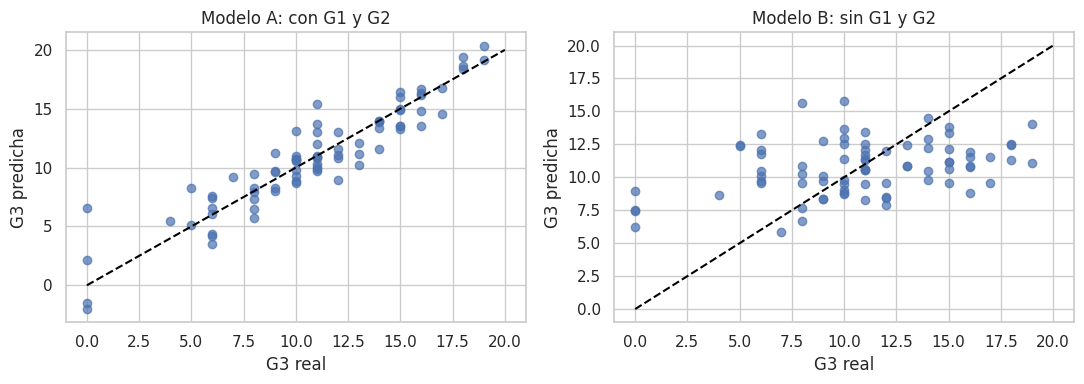

In [ ]:
modelos_lineales = {}
predicciones_lineales = {}
filas_resultado = []
y_entrenamiento = objetivo_reg.iloc[idx_entrenamiento]
y_prueba = objetivo_reg.iloc[idx_prueba]
for nombre, columnas in [('Modelo A: con G1 y G2', columnas_A), ('Modelo B: sin G1 y G2', columnas_B)]:
    tuberia = Pipeline(steps=[('preprocesamiento', construir_preprocesador(columnas)),
                              ('regresion', LinearRegression())])
    tuberia.fit(datos.iloc[idx_entrenamiento][columnas], y_entrenamiento)
    pred = tuberia.predict(datos.iloc[idx_prueba][columnas])
    modelos_lineales[nombre] = tuberia; predicciones_lineales[nombre] = pred
    filas_resultado.append({'modelo': nombre, 'MSE': mean_squared_error(y_prueba,pred),
                            'RMSE': np.sqrt(mean_squared_error(y_prueba,pred)), 'R2': r2_score(y_prueba,pred)})
resultados_lineales = pd.DataFrame(filas_resultado).set_index('modelo').round(4)
display(resultados_lineales)
fig, ax = plt.subplots(1,2,figsize=(11,4))
for grafico,(nombre,pred) in zip(ax,predicciones_lineales.items()):
    grafico.scatter(y_prueba,pred,alpha=.7)
    grafico.plot([0,20],[0,20],ls='--',color='black')
    grafico.set_title(nombre);grafico.set_xlabel('G3 real');grafico.set_ylabel('G3 predicha')
plt.tight_layout();plt.show()

In [ ]:
# Cálculo manual del MSE usando exclusivamente NumPy, sobre los mismos datos de prueba.
pred_B = predicciones_lineales['Modelo B: sin G1 y G2']
mse_manual = np.mean((y_prueba.to_numpy() - pred_B)**2)
mse_sklearn = mean_squared_error(y_prueba, pred_B)
print('MSE manual (NumPy):',round(mse_manual,8))
print('MSE scikit-learn:',round(mse_sklearn,8))
assert np.isclose(mse_manual, mse_sklearn)
print('Comprobación correcta: los resultados coinciden.')

MSE manual (NumPy): 16.90745452
MSE scikit-learn: 16.90745452
Comprobación correcta: los resultados coinciden.


### Interpretación y fuga de datos
El Modelo A consigue **R² ≈ 0,856** y **RMSE ≈ 1,664**, mientras el Modelo B obtiene **R² ≈ 0,124** y **RMSE ≈ 4,112** en esta partición. Las notas `G1` y `G2` contienen información cercana al resultado final, por eso mejoran considerablemente la predicción. **No son fuga por sí solas** si ya existen cuando se usa el modelo; **sí habría fuga temporal** si queremos actuar antes de que se conozcan y aun así las usamos como predictores. Para una alerta temprana recomendamos el Modelo B, con cautela por su rendimiento limitado.

## Registro de aporte personal

- **Qué revisé o cambié:** (describir antes de hacer el commit).
- **Qué aprendí:** (escribir con mis propias palabras).
- **Qué resultado comprobé:** (poner un valor concreto de la ejecución).

### Uso de herramientas
El material de partida fue preparado con asistencia de ChatGPT. Cada estudiante debe declarar cualquier herramienta utilizada y describir su aportación efectiva.